# ITC 3154 Cognitive Computing - Assignment 1
### Loan approval dataset - exploratory data analysis

Pantelis Donoupoglou, Fall 2026

The goal is to explore the dataset and find which features help to predict if a loan is approved or rejected (`loan_status`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os

os.makedirs('figures', exist_ok=True)   # I save the plots here to use them in the report

## Task 1-2: Load the data and print the first 20 rows

When I first loaded the file with `pd.read_csv()` everything was in one column, because the file uses `;` and not `,`.
Also all the column names and text values start with a space (for example `' Approved'`), so I remove the spaces.

In [2]:
df = pd.read_csv('loan_approval_dataset.csv', sep=';')

# remove the extra spaces from column names and text values
df.columns = df.columns.str.strip()
for col in ['education', 'self_employed', 'loan_status']:
    df[col] = df[col].str.strip()

print(df.shape)
df.head(20)

(4269, 13)


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected
5,6,0,Graduate,Yes,4800000,13500000,10,319,6800000,8300000,13700000,5100000,Rejected
6,7,5,Graduate,No,8700000,33000000,4,678,22500000,14800000,29200000,4300000,Approved
7,8,2,Graduate,Yes,5700000,15000000,20,382,13200000,5700000,11800000,6000000,Rejected
8,9,0,Graduate,Yes,800000,2200000,20,782,1300000,800000,2800000,600000,Approved
9,10,5,Not Graduate,No,1100000,4300000,10,388,3200000,1400000,3300000,1600000,Rejected


### Basic information about the dataset

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   loan_id                   4269 non-null   int64
 1   no_of_dependents          4269 non-null   int64
 2   education                 4269 non-null   str  
 3   self_employed             4269 non-null   str  
 4   income_annum              4269 non-null   int64
 5   loan_amount               4269 non-null   int64
 6   loan_term                 4269 non-null   int64
 7   cibil_score               4269 non-null   int64
 8   residential_assets_value  4269 non-null   int64
 9   commercial_assets_value   4269 non-null   int64
 10  luxury_assets_value       4269 non-null   int64
 11  bank_asset_value          4269 non-null   int64
 12  loan_status               4269 non-null   str  
dtypes: int64(10), str(3)
memory usage: 433.7 KB


In [4]:
# check for missing values and duplicates
print(df.isnull().sum())
print('duplicates:', df.duplicated().sum())

loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64
duplicates: 0


In [5]:
df.describe()

,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2135.000000,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1232.498479,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,1.000000,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1068.000000,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,2135.000000,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,3202.000000,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,4269.000000,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07


There are no missing values and no duplicates. In `describe()` I noticed that the minimum of `residential_assets_value` is negative, which does not make sense, so I checked it below.

In [6]:
print((df['residential_assets_value'] < 0).sum())
df[df['residential_assets_value'] < 0]['residential_assets_value'].unique()

28


array([-100000])

28 rows have -100000. It is a small number of rows (0.7%) so I keep them for the exploration, but they should be fixed before training a model.

loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64
loan_status
Approved    62.215976
Rejected    37.784024
Name: proportion, dtype: float64


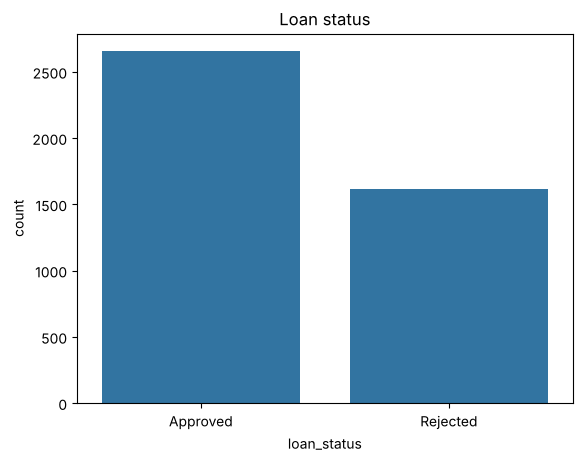

In [7]:
# how many approved / rejected
print(df['loan_status'].value_counts())
print(df['loan_status'].value_counts(normalize=True) * 100)

sns.countplot(x='loan_status', data=df)
plt.title('Loan status')
plt.savefig('figures/01_target_balance.png', dpi=150, bbox_inches='tight')
plt.show()

In [8]:
print(df['education'].value_counts())
print(df['self_employed'].value_counts())

education
Graduate        2144
Not Graduate    2125
Name: count, dtype: int64
self_employed
Yes    2150
No     2119
Name: count, dtype: int64


### Distribution of the numeric columns

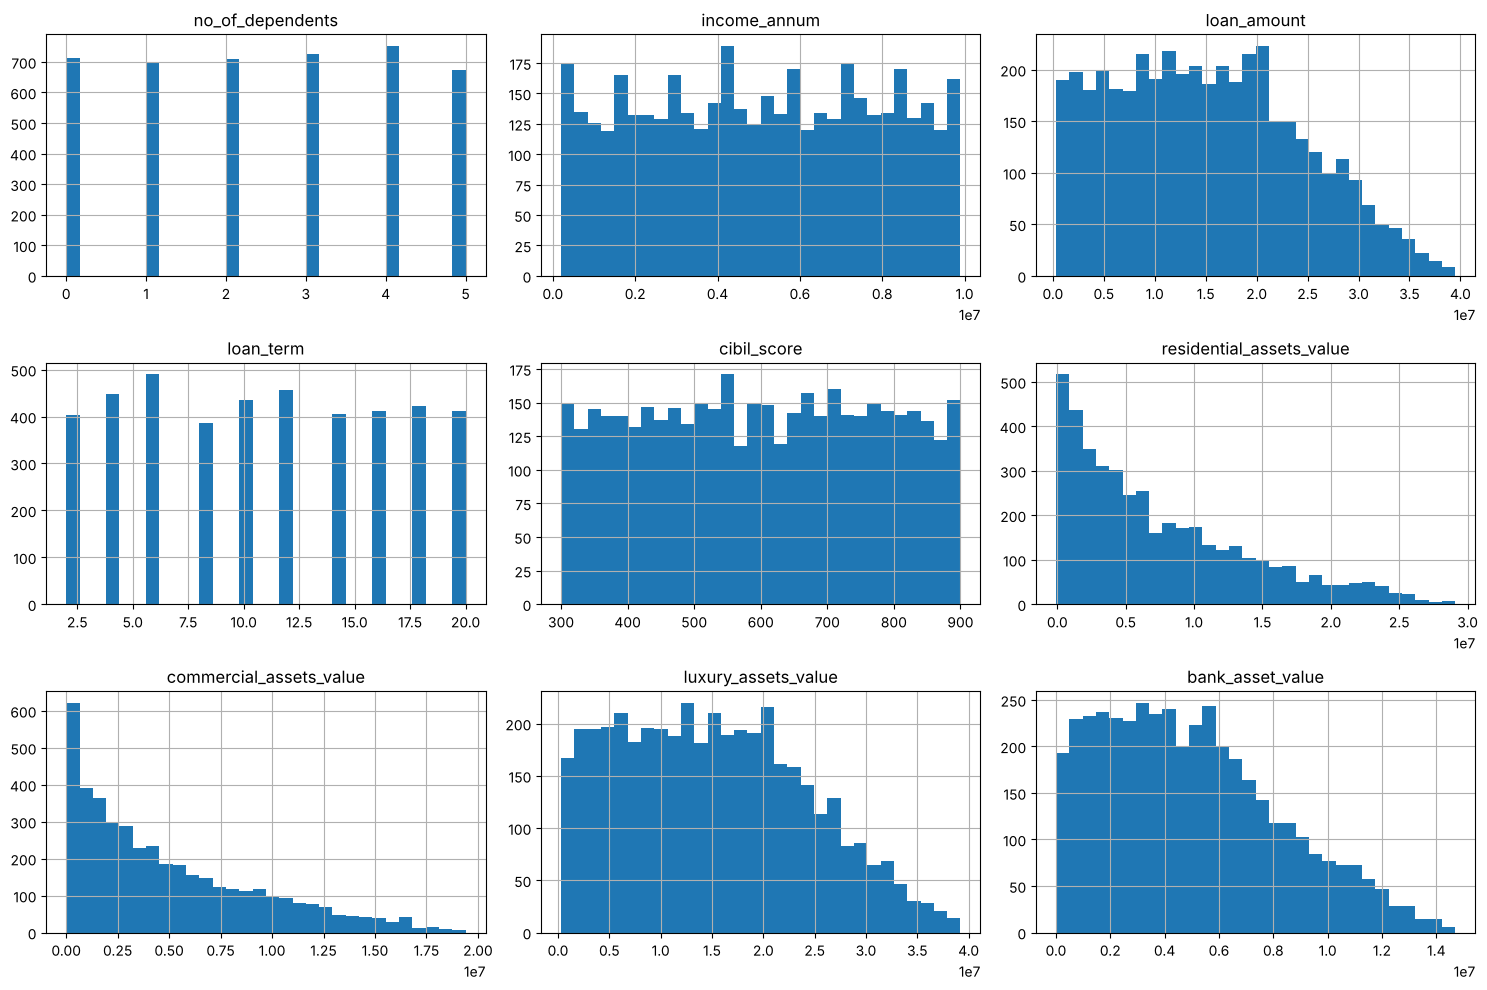

In [9]:
num_cols = ['no_of_dependents', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score',
            'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value']

df[num_cols].hist(bins=30, figsize=(15, 10))
plt.tight_layout()
plt.savefig('figures/02_histograms.png', dpi=150, bbox_inches='tight')
plt.show()

## Task 3: Which features could be important?

I filled the importance table manually in the report. Here I just compare the average values of approved and rejected loans to support it.

In [10]:
df.groupby('loan_status')[num_cols].mean()

,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
loan_status,,,,,,,,,
Approved,2.474774,5.025904e+06,1.524725e+07,10.397590,703.461973,7.399812e+06,5.001355e+06,1.501660e+07,4.959526e+06
Rejected,2.538128,5.113825e+06,1.494606e+07,11.728456,429.468072,7.592498e+06,4.926720e+06,1.530694e+07,5.004960e+06


## Task 4: Correlation heat map

`.corr()` works only with numbers, so I made a new column `loan_status_num` (Approved = 1, Rejected = 0) to see the correlation of each feature with the target. I also drop `loan_id` because it is just an ID.

In [11]:
df['loan_status_num'] = df['loan_status'].map({'Approved': 1, 'Rejected': 0})

numeric_df = df.drop(columns=['loan_id', 'education', 'self_employed', 'loan_status'])
corrmatrix = numeric_df.corr()
corrmatrix

,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status_num
no_of_dependents,1.000000,0.007266,-0.003366,-0.020111,-0.009998,0.007376,-0.001531,0.002817,0.011163,-0.018114
income_annum,0.007266,1.000000,0.927470,0.011488,-0.023034,0.636841,0.640328,0.929145,0.851093,-0.015189
loan_amount,-0.003366,0.927470,1.000000,0.008437,-0.017035,0.594596,0.603188,0.860914,0.788122,0.016150
loan_term,-0.020111,0.011488,0.008437,1.000000,0.007810,0.008016,-0.005478,0.012490,0.017177,-0.113036
cibil_score,-0.009998,-0.023034,-0.017035,0.007810,1.000000,-0.019947,-0.003769,-0.028618,-0.015478,0.770518
residential_assets_value,0.007376,0.636841,0.594596,0.008016,-0.019947,1.000000,0.414786,0.590932,0.527418,-0.014367
commercial_assets_value,-0.001531,0.640328,0.603188,-0.005478,-0.003769,0.414786,1.000000,0.591128,0.548576,0.008246
luxury_assets_value,0.002817,0.929145,0.860914,0.012490,-0.028618,0.590932,0.591128,1.000000,0.788517,-0.015465
bank_asset_value,0.011163,0.851093,0.788122,0.017177,-0.015478,0.527418,0.548576,0.788517,1.000000,-0.006778
loan_status_num,-0.018114,-0.015189,0.016150,-0.113036,0.770518,-0.014367,0.008246,-0.015465,-0.006778,1.000000


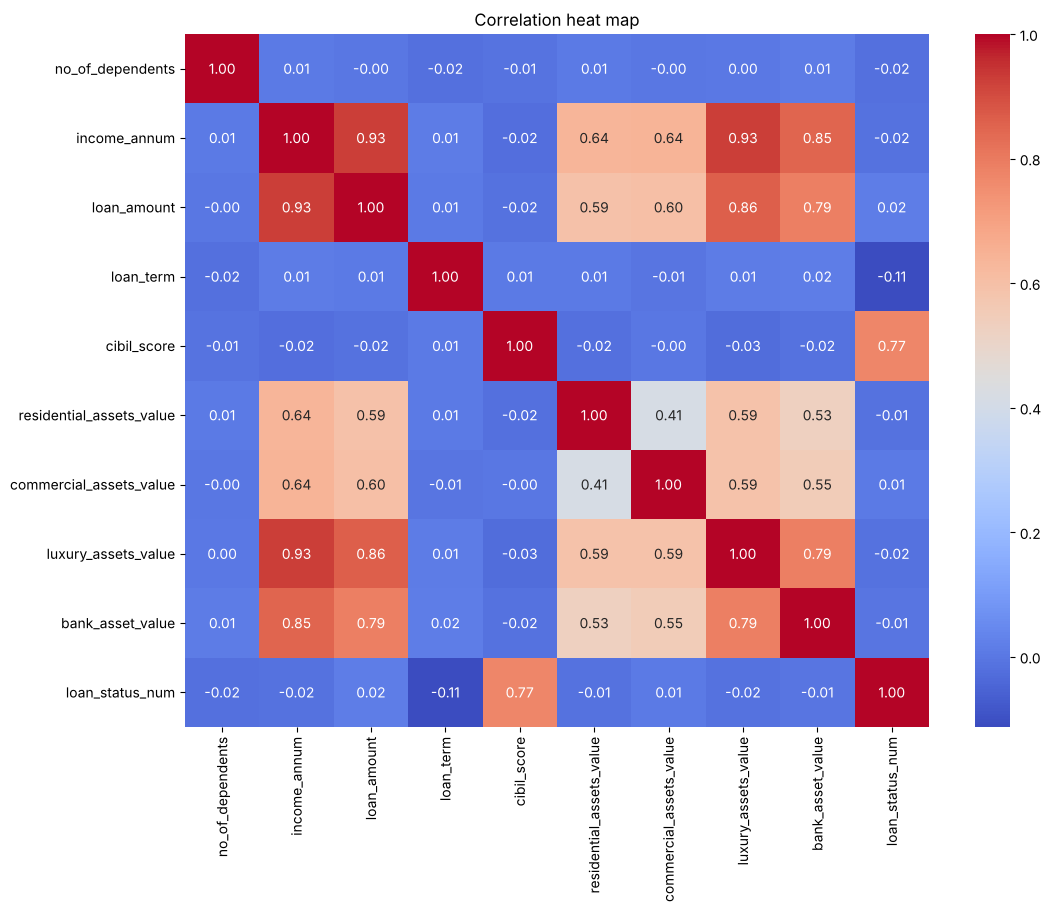

In [12]:
plt.figure(figsize=(12, 9))
sns.heatmap(corrmatrix, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation heat map')
plt.savefig('figures/03_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

loan_term                  -0.113036
no_of_dependents           -0.018114
luxury_assets_value        -0.015465
income_annum               -0.015189
residential_assets_value   -0.014367
bank_asset_value           -0.006778
commercial_assets_value     0.008246
loan_amount                 0.016150
cibil_score                 0.770518
Name: loan_status_num, dtype: float64


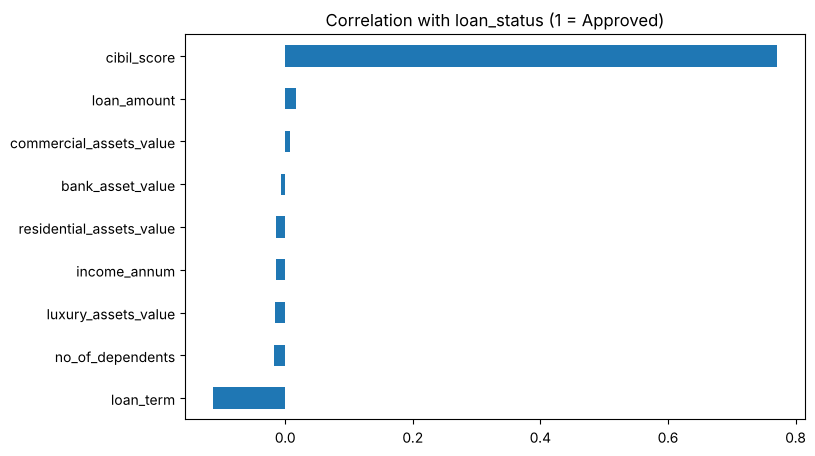

In [13]:
# correlation of every feature with loan_status, sorted
corr_target = corrmatrix['loan_status_num'].drop('loan_status_num').sort_values()
print(corr_target)

corr_target.plot(kind='barh', figsize=(8, 5))
plt.title('Correlation with loan_status (1 = Approved)')
plt.savefig('figures/04_target_correlation.png', dpi=150, bbox_inches='tight')
plt.show()

## Task 5: Effect of the numeric features on loan_status

Only `cibil_score` and `loan_term` seem to have a correlation with the target. To check this better I made box plots for all numeric features.

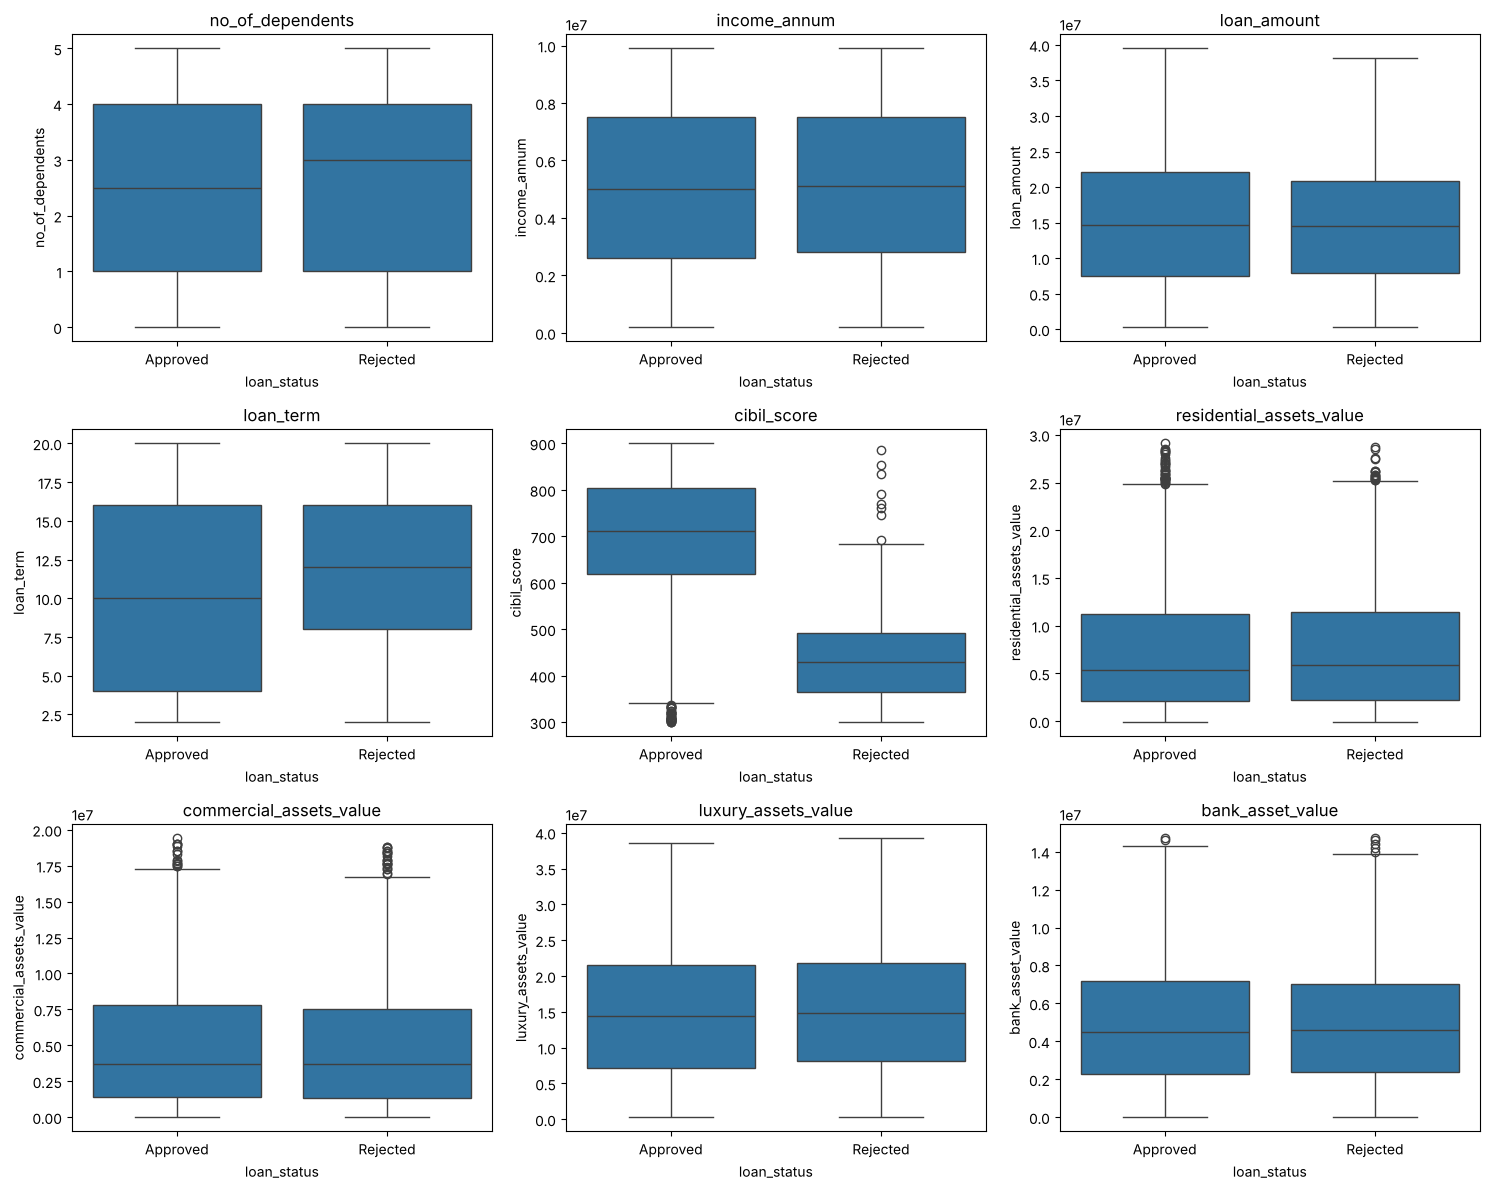

In [14]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(x='loan_status', y=col, data=df, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.savefig('figures/05_boxplots.png', dpi=150, bbox_inches='tight')
plt.show()

### CIBIL score

cibil_range
300-400    10.112360
400-500    11.239193
500-550    10.182768
550-600    99.436620
600-700    99.428571
700-800    99.455041
800-900    99.565847
Name: loan_status_num, dtype: float64


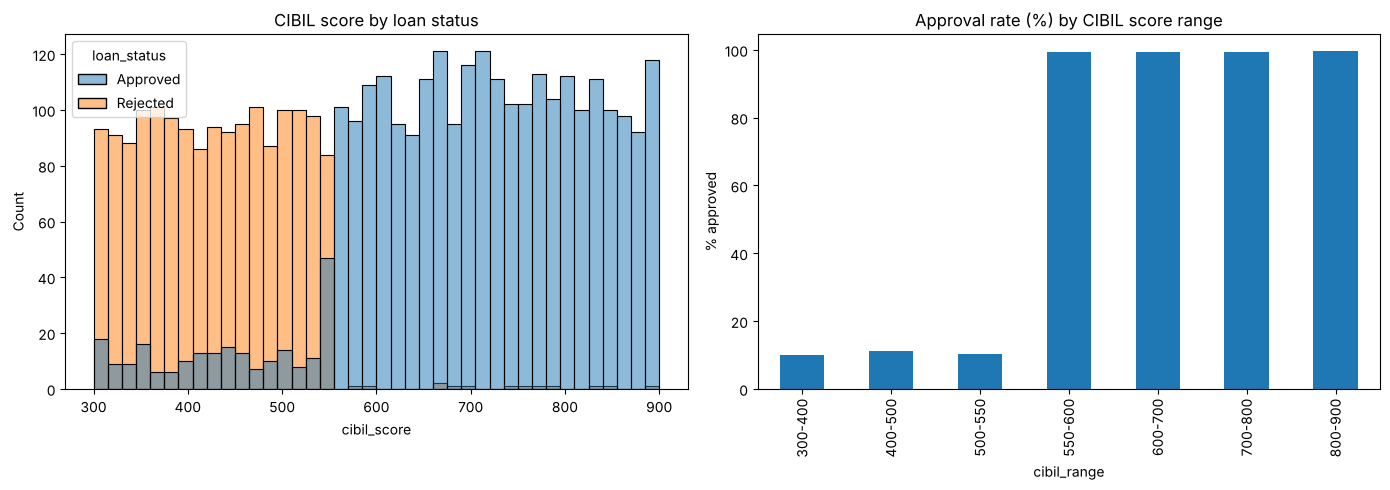

In [15]:
# approval rate for different ranges of cibil score
df['cibil_range'] = pd.cut(df['cibil_score'], bins=[300, 400, 500, 550, 600, 700, 800, 900],
                           labels=['300-400', '400-500', '500-550', '550-600', '600-700', '700-800', '800-900'],
                           include_lowest=True)
cibil_rate = df.groupby('cibil_range', observed=True)['loan_status_num'].mean() * 100
print(cibil_rate)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(x='cibil_score', hue='loan_status', data=df, bins=40, ax=axes[0])
axes[0].set_title('CIBIL score by loan status')
cibil_rate.plot(kind='bar', ax=axes[1])
axes[1].set_title('Approval rate (%) by CIBIL score range')
axes[1].set_ylabel('% approved')
plt.tight_layout()
plt.savefig('figures/06_cibil.png', dpi=150, bbox_inches='tight')
plt.show()

In [16]:
# what if we just approve everyone with cibil score >= 550 ?
prediction = (df['cibil_score'] >= 550).astype(int)
print('correct:', (prediction == df['loan_status_num']).mean() * 100, '%')

correct: 95.36191145467322 %


### Loan term

loan_term
2     77.970297
4     81.879195
6     57.551020
8     56.994819
10    52.522936
12    60.526316
14    59.012346
16    57.281553
18    60.900474
20    57.420925
Name: loan_status_num, dtype: float64


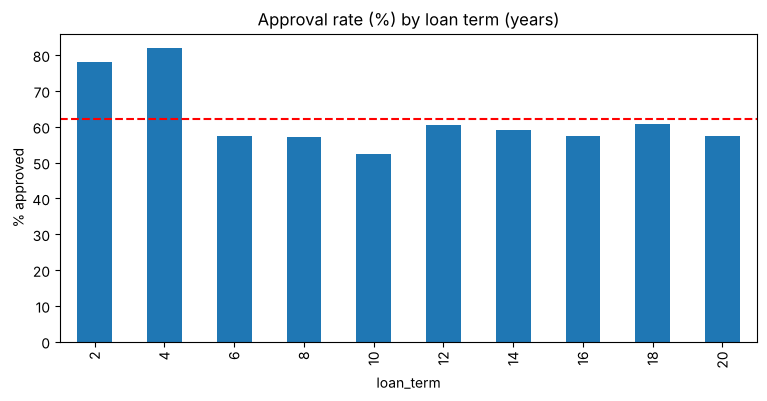

In [17]:
term_rate = df.groupby('loan_term')['loan_status_num'].mean() * 100
print(term_rate)

term_rate.plot(kind='bar', figsize=(9, 4))
plt.axhline(df['loan_status_num'].mean() * 100, color='red', linestyle='--')  # overall approval rate
plt.title('Approval rate (%) by loan term (years)')
plt.ylabel('% approved')
plt.savefig('figures/07_loan_term.png', dpi=150, bbox_inches='tight')
plt.show()

## Task 5: Categorical feature - education

I chose `education` because I expected graduates to get loans more easily.
I use a crosstab and the chi-square test from SciPy.
H0: education and loan_status are independent. If p < 0.05 we reject H0.

In [18]:
table = pd.crosstab(df['education'], df['loan_status'])
print(table)
print()
print(pd.crosstab(df['education'], df['loan_status'], normalize='index') * 100)

chi2, p, dof, expected = stats.chi2_contingency(table)
print()
print('chi2 =', round(chi2, 3), ' p-value =', round(p, 3))

loan_status   Approved  Rejected
education                       
Graduate          1339       805
Not Graduate      1317       808

loan_status    Approved   Rejected
education                         
Graduate      62.453358  37.546642
Not Graduate  61.976471  38.023529

chi2 = 0.084  p-value = 0.772


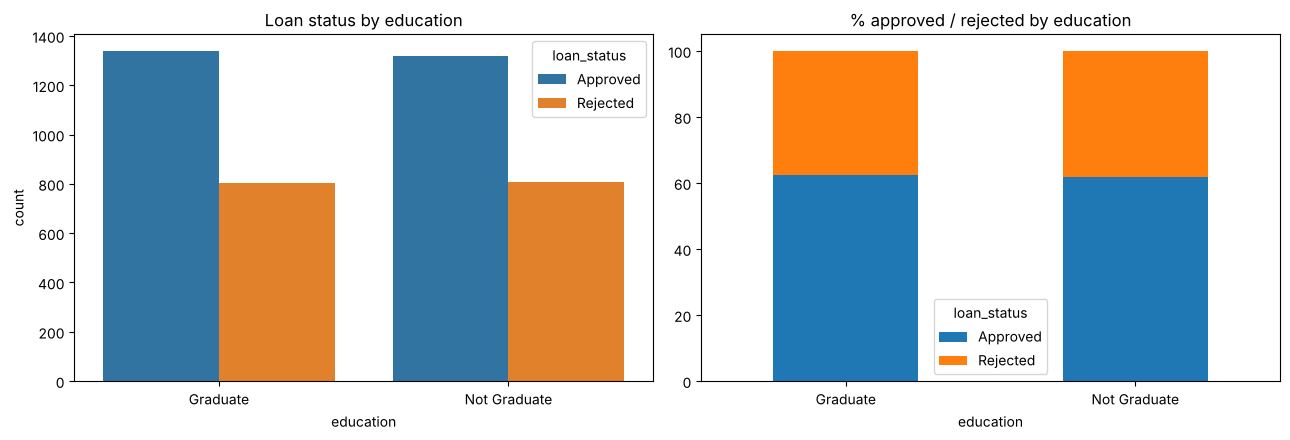

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(x='education', hue='loan_status', data=df, ax=axes[0])
axes[0].set_title('Loan status by education')
(pd.crosstab(df['education'], df['loan_status'], normalize='index') * 100).plot(kind='bar', stacked=True, ax=axes[1])
axes[1].set_title('% approved / rejected by education')
axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.savefig('figures/08_education.png', dpi=150, bbox_inches='tight')
plt.show()

In [20]:
# I also checked self_employed the same way
table2 = pd.crosstab(df['self_employed'], df['loan_status'])
print(pd.crosstab(df['self_employed'], df['loan_status'], normalize='index') * 100)
chi2, p, dof, expected = stats.chi2_contingency(table2)
print('chi2 =', round(chi2, 3), ' p-value =', round(p, 3))

loan_status     Approved   Rejected
self_employed                      
No             62.199151  37.800849
Yes            62.232558  37.767442
chi2 = 0.0  p-value = 1.0


In [21]:
# do graduates have a better cibil score or income? (if yes, education could matter indirectly)
df.groupby('education')[['cibil_score', 'income_annum']].mean()

,cibil_score,income_annum
education,,
Graduate,599.138060,5.091604e+06
Not Graduate,600.741176,5.026353e+06


## Conclusions
- `cibil_score` is the most important feature (correlation 0.77). Below 550 almost all loans are rejected and above 550 almost all are approved.
- `loan_term` has a small negative effect (-0.11). Short loans (2-4 years) are approved more often.
- Income, loan amount and assets are very correlated with each other but they have almost no correlation with loan_status.
- `education` and `self_employed` have no effect on approval (chi-square p > 0.05).